# Mạng nơ-ron nhiều lớp với scikit-learn: nhận dạng chữ số viết tay

*Bài 9, mục 9.1.3.* `MLPClassifier` cài đặt mạng nơ-ron truyền thẳng nhiều lớp (Multilayer Perceptron), huấn luyện bằng lan truyền ngược với các thuật toán tối ưu `adam` (mặc định), `sgd`.

Dữ liệu `load_digits`: 1797 ảnh xám $8 \times 8$ chữ số viết tay 0 – 9; mỗi ảnh là vector 64 đặc trưng (độ sáng pixel 0 – 16).

Kích thước: (1797, 64)


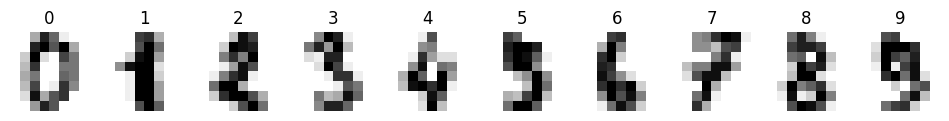

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()
X, y = digits.data, digits.target
print('Kích thước:', X.shape)
fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for ax, image, label in zip(axes, digits.images, digits.target):
    ax.imshow(image, cmap='gray_r'); ax.set_title(label); ax.axis('off')
plt.show()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

## 1. Huấn luyện mạng 64 – 64 – 10

Lớp ra có 10 nơ-ron với softmax; hàm mất mát cross-entropy. Chuẩn hóa đặc trưng giúp tối ưu hội tụ nhanh hơn.

In [2]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

model = make_pipeline(StandardScaler(),
                      MLPClassifier(hidden_layer_sizes=(64,), activation='relu', solver='adam',
                                    learning_rate_init=0.001, max_iter=300, random_state=0))
model.fit(X_train, y_train)
mlp = model[-1]
print('Số epoch: %d, loss cuối: %.4f' % (mlp.n_iter_, mlp.loss_))
print('Kích thước ma trận trọng số:', [W.shape for W in mlp.coefs_])
print('Tổng số tham số:', sum(W.size for W in mlp.coefs_) + sum(b.size for b in mlp.intercepts_))
print('Độ chính xác huấn luyện: %.4f' % model.score(X_train, y_train))
print('Độ chính xác kiểm tra  : %.4f' % model.score(X_test, y_test))

Số epoch: 172, loss cuối: 0.0065
Kích thước ma trận trọng số: [(64, 64), (64, 10)]
Tổng số tham số: 4810
Độ chính xác huấn luyện: 1.0000
Độ chính xác kiểm tra  : 0.9733


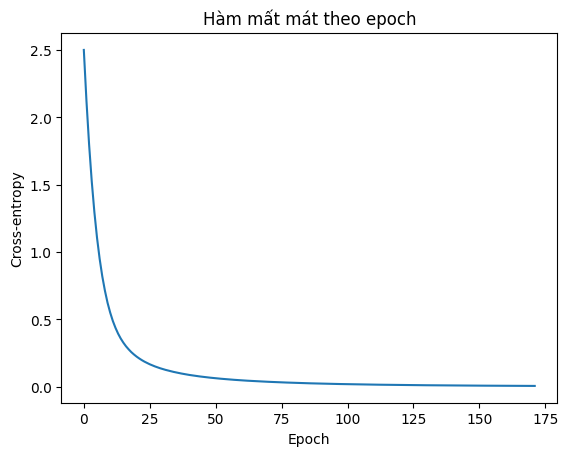

In [3]:
plt.plot(mlp.loss_curve_)
plt.xlabel('Epoch'); plt.ylabel('Cross-entropy'); plt.title('Hàm mất mát theo epoch')
plt.show()

## 2. Đánh giá

In [4]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = model.predict(X_test)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, digits=3))

[[45  0  0  0  0  0  0  0  0  0]
 [ 0 45  0  0  0  0  1  0  0  0]
 [ 0  0 44  0  0  0  0  0  0  0]
 [ 0  0  1 44  0  0  0  1  0  0]
 [ 0  0  0  0 44  0  0  0  1  0]
 [ 0  0  0  0  0 45  0  0  1  0]
 [ 0  1  0  0  0  0 44  0  0  0]
 [ 0  0  0  0  0  0  0 45  0  0]
 [ 0  2  0  0  0  1  0  0 40  0]
 [ 0  0  0  2  0  1  0  0  0 42]]
              precision    recall  f1-score   support

           0      1.000     1.000     1.000        45
           1      0.938     0.978     0.957        46
           2      0.978     1.000     0.989        44
           3      0.957     0.957     0.957        46
           4      1.000     0.978     0.989        45
           5      0.957     0.978     0.968        46
           6      0.978     0.978     0.978        45
           7      0.978     1.000     0.989        45
           8      0.952     0.930     0.941        43
           9      1.000     0.933     0.966        45

    accuracy                          0.973       450
   macro avg      0

`predict_proba` trả về đầu ra softmax: phân phối xác suất trên 10 lớp.

In [5]:
proba = model.predict_proba(X_test[:1])[0]
print('Xác suất mỗi chữ số:', proba.round(3))
print('Dự đoán:', proba.argmax(), ' nhãn thật:', y_test[0])

Xác suất mỗi chữ số: [0.005 0.    0.959 0.03  0.001 0.    0.    0.    0.    0.005]
Dự đoán: 2  nhãn thật: 2


## 3. Ảnh hưởng của kiến trúc

Các cấu hình được định trước để minh họa. Không chọn kiến trúc theo điểm test này. Mạng 5 nơ-ron có accuracy train 0.9911 và test 0.9000: khoảng cách tổng quát hóa lớn, chưa đủ cơ sở kết luận underfitting. Cần xem train/validation loss, hội tụ và nhiều lần khởi tạo hoặc CV.

In [6]:
for hidden in [(5,), (16,), (64,), (256,), (64, 32)]:
    model = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=hidden, max_iter=2000, random_state=0))
    model.fit(X_train, y_train)
    n_params = sum(W.size for W in model[-1].coefs_) + sum(b.size for b in model[-1].intercepts_)
    print('Lớp ẩn %-9s: %6d tham số, huấn luyện %.4f, kiểm tra %.4f'
          % (hidden, n_params, model.score(X_train, y_train), model.score(X_test, y_test)))

Lớp ẩn (5,)     :    385 tham số, huấn luyện 0.9911, kiểm tra 0.9000


Lớp ẩn (16,)    :   1210 tham số, huấn luyện 1.0000, kiểm tra 0.9600


Lớp ẩn (64,)    :   4810 tham số, huấn luyện 1.0000, kiểm tra 0.9733


Lớp ẩn (256,)   :  19210 tham số, huấn luyện 1.0000, kiểm tra 0.9756


Lớp ẩn (64, 32) :   6570 tham số, huấn luyện 1.0000, kiểm tra 0.9644


## 4. So sánh với các mô hình khác

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

for name, clf in [('Hồi quy Logistic', LogisticRegression(max_iter=2000)),
                  ('Cây quyết định', DecisionTreeClassifier(random_state=0)),
                  ('SVM RBF', SVC()),
                  ('MLP (64,)', MLPClassifier(hidden_layer_sizes=(64,), max_iter=300, random_state=0))]:
    model = make_pipeline(StandardScaler(), clf).fit(X_train, y_train)
    print('%-17s kiểm tra %.4f' % (name, model.score(X_test, y_test)))

Hồi quy Logistic  kiểm tra 0.9689
Cây quyết định    kiểm tra 0.8556


SVM RBF           kiểm tra 0.9822


MLP (64,)         kiểm tra 0.9733
